<a href="https://colab.research.google.com/github/amansingh4847/NLP/blob/main/unit2/%20Information%20Retrieval%20System%20with%20Ranking%20using%20TF-IDF.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


INFORMATION RETRIEVAL RESULTS
Search Query: machine learning and artificial intelligence

Ranked Documents:

 Rank    Document  Similarity Score                                                     Content
    1  Document 1            0.8551     Machine learning is a branch of artificial intelligence
    2  Document 7            0.4156   Artificial intelligence is transforming modern technology
    3  Document 8            0.3367       Data science involves statistics and machine learning
    4  Document 2            0.1339     Deep learning uses neural networks for complex problems
    5  Document 9            0.0000         Search engines use information retrieval techniques
    6 Document 10            0.0000      Computer networks enable communication between devices
    7  Document 5            0.0000         TF IDF is used for document ranking and text search
    8  Document 6            0.0000 Natural language processing helps computers understand text
    9  Document 3         

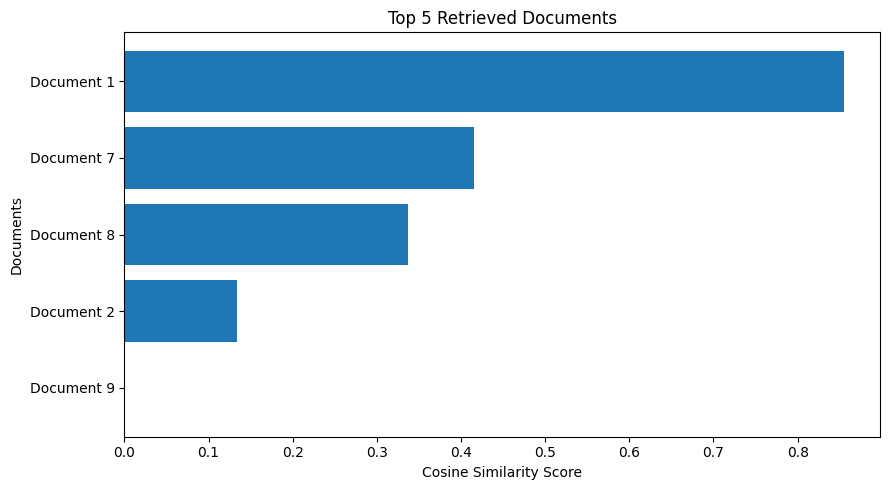


CUSTOM SEARCH RESULTS
Query: Python programming language
Document 3 | Score: 0.8552
Python is a popular programming language

Document 6 | Score: 0.1763
Natural language processing helps computers understand text

Document 9 | Score: 0.0000
Search engines use information retrieval techniques

Document 10 | Score: 0.0000
Computer networks enable communication between devices

Document 7 | Score: 0.0000
Artificial intelligence is transforming modern technology

Information Retrieval Completed Successfully!


In [9]:

# Information Retrieval System with Ranking using TF-IDF

!pip install -q scikit-learn pandas matplotlib

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Sample document collection
documents = [
    "Machine learning is a branch of artificial intelligence",
    "Deep learning uses neural networks for complex problems",
    "Python is a popular programming language",
    "Information retrieval helps users find relevant documents",
    "TF IDF is used for document ranking and text search",
    "Natural language processing helps computers understand text",
    "Artificial intelligence is transforming modern technology",
    "Data science involves statistics and machine learning",
    "Search engines use information retrieval techniques",
    "Computer networks enable communication between devices"
]

# Document titles
titles = [f"Document {i+1}" for i in range(len(documents))]

# TF-IDF vectorization
vectorizer = TfidfVectorizer(stop_words='english')
tfidf_matrix = vectorizer.fit_transform(documents)

# Search query
query = "machine learning and artificial intelligence"

# Convert query into TF-IDF vector
query_vector = vectorizer.transform([query])

# Calculate cosine similarity
similarity_scores = cosine_similarity(
    query_vector, tfidf_matrix
).flatten()

# Rank documents
ranked_indices = similarity_scores.argsort()[::-1]

# Display ranked results
results = []

for rank, index in enumerate(ranked_indices, start=1):
    results.append({
        'Rank': rank,
        'Document': titles[index],
        'Similarity Score': round(similarity_scores[index], 4),
        'Content': documents[index]
    })

results_df = pd.DataFrame(results)

print("\nINFORMATION RETRIEVAL RESULTS")
print("Search Query:", query)
print("\nRanked Documents:\n")
print(results_df.to_string(index=False))

# Visualize top 5 results
top_results = results_df.head(5)

plt.figure(figsize=(9, 5))
plt.barh(
    top_results['Document'][::-1],
    top_results['Similarity Score'][::-1]
)
plt.xlabel("Cosine Similarity Score")
plt.ylabel("Documents")
plt.title("Top 5 Retrieved Documents")
plt.tight_layout()
plt.show()

# Custom search
custom_query = "Python programming language"
custom_vector = vectorizer.transform([custom_query])

custom_scores = cosine_similarity(
    custom_vector, tfidf_matrix
).flatten()

print("\nCUSTOM SEARCH RESULTS")
print("Query:", custom_query)

for index in custom_scores.argsort()[::-1][:5]:
    print(
        f"{titles[index]} | Score: {custom_scores[index]:.4f}"
        f"\n{documents[index]}\n"
    )

print("Information Retrieval Completed Successfully!")
